# Praktikum 1: regresi linier rating kafe

In [1]:
# Langkah 2: Import Library

# import package
import numpy as np
import pandas as pd

In [2]:
# Langkah 3: Baca Data

# baca data dari file CSV
data = pd.read_csv('../../dataset_pbl/cafes.csv')

In [3]:
# Langkah 4: Pemahaman Terhadap Data

# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   cafe_id        302 non-null    str    
 1   name           302 non-null    str    
 2   address        302 non-null    str    
 3   latitude       302 non-null    float64
 4   longitude      302 non-null    float64
 5   rating         302 non-null    float64
 6   review_count   302 non-null    int64  
 7   categories     302 non-null    str    
 8   phone          222 non-null    str    
 9   website        124 non-null    str    
 10  price_range    265 non-null    str    
 11  price_min      265 non-null    float64
 12  price_max      265 non-null    float64
 13  opening_hours  296 non-null    str    
 14  scraped_at     302 non-null    str    
 15  source_query   176 non-null    str    
dtypes: float64(5), int64(1), str(10)
memory usage: 143.0 KB


,latitude,longitude,rating,review_count,price_min,price_max
count,302.000000,302.000000,302.000000,302.000000,265.000000,265.000000
mean,-7.958872,112.629606,4.654636,868.539735,15747.505660,22924.864151
std,0.013686,0.016089,0.241868,1409.505148,14506.693523,23444.357890
min,-7.994386,112.603491,3.200000,1.000000,1.000000,1.000000
25%,-7.969487,112.618566,4.500000,92.000000,1.000000,1.000000
50%,-7.959989,112.625814,4.700000,370.500000,25000.000000,25000.000000
75%,-7.946633,112.639973,4.800000,1056.750000,25000.000000,25000.000000
max,-7.926703,112.672867,5.000000,14193.000000,75000.000000,150000.000000


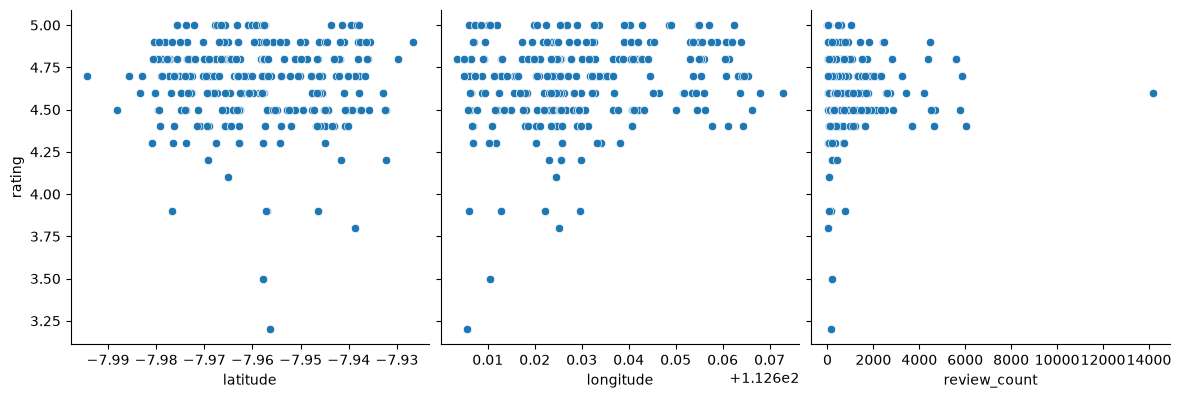

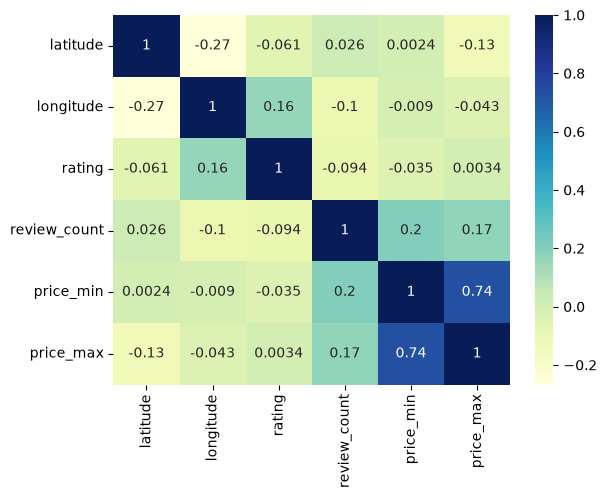

In [4]:
# Langkah 5: Visualisasi Data

# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Import library Matplotlib dan Seaborn untuk visualisasi data.
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['latitude', 'longitude', 'review_count'],
             y_vars='rating', height=4, aspect=1, kind='scatter')
plt.show()

# Gunakan pairplot untuk menampilkan hubungan antara variabel bebas dan variabel target dalam bentuk scatter plot.
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

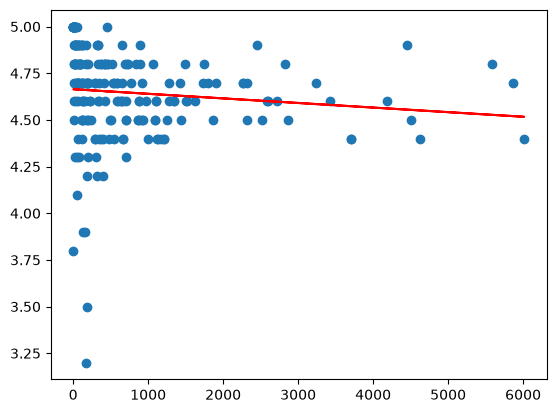

In [5]:
# Langkah 6: Regresi Linier

# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['review_count']
y = data['rating']

# Pisahkan variabel bebas (X) dan variabel target (y).
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Bagi data menjadi data latih (70%) dan data uji (30%) menggunakan train_test_split.
# Lakukan training model regresi linier menggunakan library StatsModels. Tambahkan konstanta (intercept) ke variabel bebas.
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Visualisasikan garis regresi pada data latih.
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, lr.predict(X_train_sm), 'r')
plt.show()

C:\Users\Andre\AppData\Local\Temp\ipykernel_36020\1346121166.py:12: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


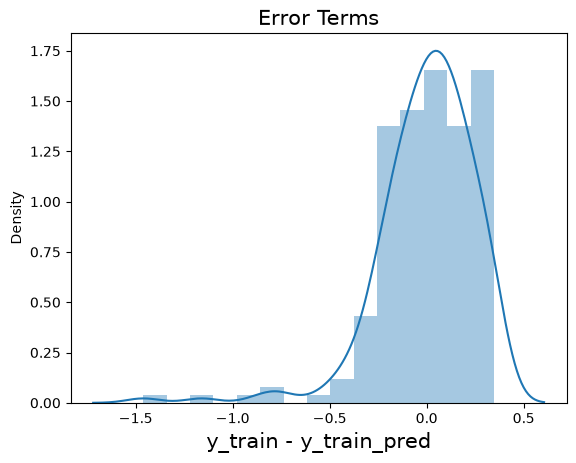

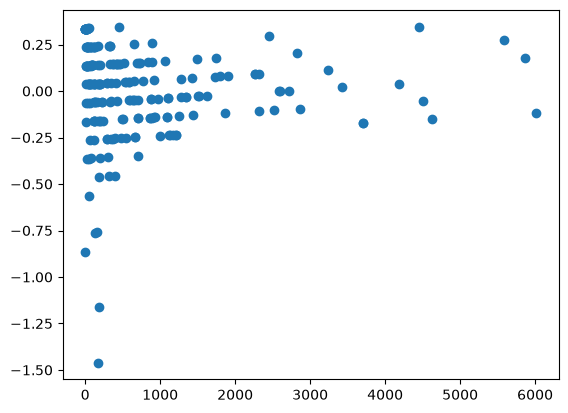

In [6]:
# Langkah 7: Analisis Residual

# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

# Lakukan prediksi nilai y dari data latih dan hitung residual (selisih antara nilai sebenarnya dan nilai prediksi).
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [7]:
#Langkah 8: Prediksi pada Data Uji dan Evaluasi Model

# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

#Lakukan prediksi pada data uji.
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)
print('R-squared:', r_squared)

R-squared: -0.03305294806561987


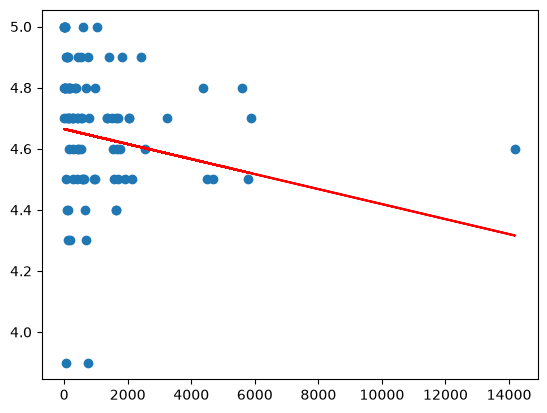

In [8]:
# Langkah 9: Visualisasi Hasil

# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()